In [2]:
# Instalación de dependencias

!pip install -q transformers datasets evaluate huggingface_hub scikit-learn

# Registro de versiones para que el experimento sea reproducible
import importlib.metadata as md

paquetes = ["torch", "torchvision", "transformers", "datasets", "evaluate",
            "huggingface_hub", "scikit-learn", "pandas", "matplotlib", "Pillow"]

with open("requirements.txt", "w") as f:
    for p in paquetes:
        v = md.version(p)
        print(f"{p:<16} {v}")
        f.write(f"{p}=={v}\n")

print("\nrequirements.txt generado")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 953.3 kB/s eta 0:00:00
torch            2.11.0+cpu
torchvision      0.26.0+cpu
transformers     5.18.0
datasets         4.8.5
evaluate         0.4.6
huggingface_hub  1.33.0
scikit-learn     1.6.1
pandas           2.2.3
matplotlib       3.10.0
Pillow           11.3.0

requirements.txt generado


In [3]:
#  Autenticación en Hugging Face Hub
import os
from huggingface_hub import login, whoami

try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")
except Exception:
    token = None  # no hay secret o no tiene acceso al cuaderno

if token:
    os.environ["HF_TOKEN"] = token
    login(token=token, add_to_git_credential=False)
else:
    login()  # alternativa: pide el token de forma interactiva

print("Sesión iniciada como:", whoami()["name"])

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Sesión iniciada como: RabindranathMunoz


In [4]:
#  Carga de modelos y datasets
import random
import numpy as np
import pandas as pd
import torch
from transformers import (AutoImageProcessor, AutoModelForImageClassification,
                          MobileNetV2ImageProcessor, ConvNextImageProcessor)

# Semilla fija: solo interviene al muestrear el dataset de campo (la inferencia es determinista).
# Se usa 42 por convención; el valor no importa, lo que importa es fijarlo para obtener la misma muestra en cada ejecución.
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# Clases del caso de uso: app de salud de la hoja de maíz
CLASES = ["Tizón", "Roya común", "Mancha gris", "Sana"]

def clase_maiz(etiqueta):
    """Traduce una etiqueta de PlantVillage (38 clases) a una de las 4 clases de maíz; None si no es maíz."""
    e = etiqueta.lower()
    if "corn" not in e and "maize" not in e:
        return None
    if "blight" in e:
        return "Tizón"
    if "rust" in e:
        return "Roya común"
    if "cercospora" in e or "gray" in e:
        return "Mancha gris"
    if "healthy" in e:
        return "Sana"
    return None

In [5]:
# Repositorio y commit exacto de cada modelo (revision) para que la descarga sea reproducible
MODELOS = {
    "MobileNetV2": ("linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification",
                    "c1861579a670fb6232258805b801cd4137cb7176"),
    "ResNet-50":   ("mesabo/agri-plant-disease-resnet50",
                    "61aa6c309c8e023f1cef5761254039254fddebed"),
    "ViT-base":    ("kimcomehome/plantvillage-vit-leaf-disease",
                    "9328047a2fa94eb09a5dc7a2a0644a82e8a89499"),
}

In [6]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Los repos de MobileNetV2 y ResNet-50 declaran clases antiguas (MobileNetV2FeatureExtractor y
# ConvNextFeatureExtractor) que transformers ya eliminó, y AutoImageProcessor no las reconoce.
# Se cargan con la clase actual equivalente, que lee el mismo preprocessor_config.json.
PROCESADOR = {"MobileNetV2": MobileNetV2ImageProcessor, "ResNet-50": ConvNextImageProcessor}

modelos, procesadores, resumen_modelos = {}, {}, []

for nombre, (repo, rev) in MODELOS.items():
    procesadores[nombre] = PROCESADOR.get(nombre, AutoImageProcessor).from_pretrained(repo, revision=rev)
    modelo = AutoModelForImageClassification.from_pretrained(repo, revision=rev).to(DEVICE).eval()
    modelos[nombre] = modelo

    etiquetas_maiz = {e: clase_maiz(e) for e in modelo.config.id2label.values() if clase_maiz(e)}
    assert sorted(etiquetas_maiz.values()) == sorted(CLASES), f"{nombre}: faltan clases de maíz"

    parametros = sum(p.numel() for p in modelo.parameters())
    resumen_modelos.append({
        "Modelo": nombre,
        "Arquitectura": modelo.config.model_type,
        "Parámetros (M)": round(parametros / 1e6, 1),
        "Tamaño en memoria (MB)": round(sum(p.numel() * p.element_size() for p in modelo.parameters()) / 1e6, 1),
        "Clases totales": len(modelo.config.id2label),
        "Clases de maíz": len(etiquetas_maiz),
    })

print("Dispositivo:", DEVICE)
display(pd.DataFrame(resumen_modelos))

preprocessor_config.json:   0%|          | 0.00/408 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 9.34MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 9.26MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Dispositivo: cpu


,Modelo,Arquitectura,Parámetros (M),Tamaño en memoria (MB),Clases totales,Clases de maíz
0,MobileNetV2,mobilenet_v2,2.3,9.1,38,4
1,ResNet-50,resnet,23.6,94.3,38,4
2,ViT-base,vit,85.8,343.3,38,4


README.md:   0%|          | 0.00/617 [00:00<?, ?B/s]

data/train-00000-of-00001-3b1e0906129238(…): reconstructing file:   0%|          |  0.00B /  124MB            

data/train-00000-of-00001-3b1e0906129238(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-b481d86c0eb1075(…): reconstructing file:   0%|          |  0.00B / 45.7MB            

data/test-00000-of-00001-b481d86c0eb1075(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3350 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/838 [00:00<?, ? examples/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 800 files:   0%|          | 0/800 [00:00<?, ?it/s]

,Laboratorio,Campo
Tizón,225,200
Roya común,275,200
Mancha gris,113,200
Sana,225,200
Total,838,800


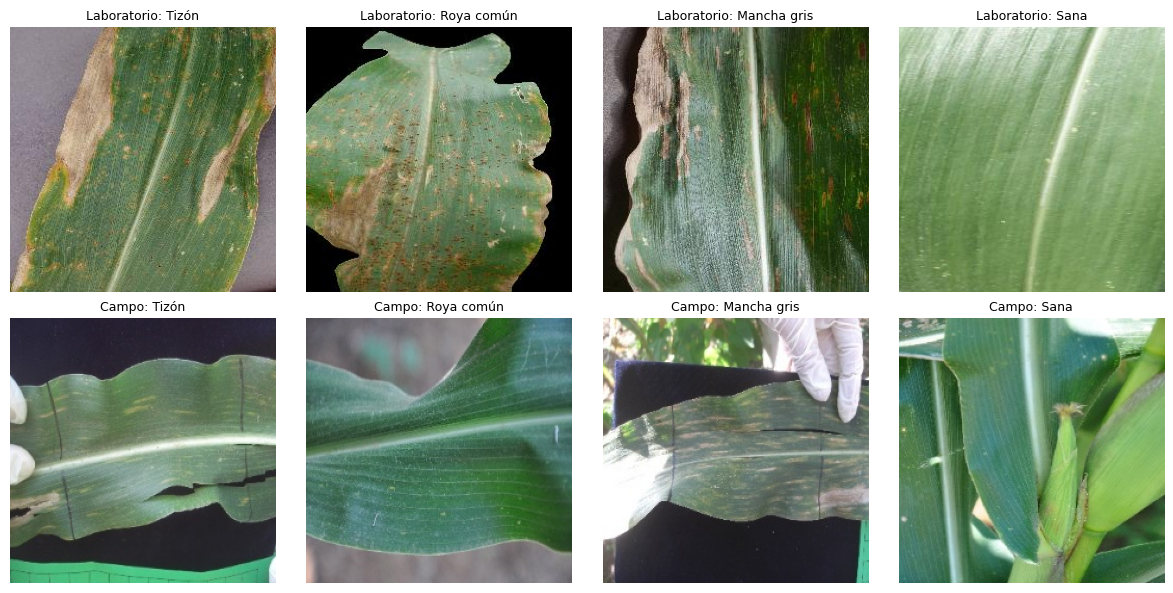

In [7]:
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset, Image as ImagenHF
from huggingface_hub import HfApi, snapshot_download

def preparar(ds, mapeo):
    """Se queda con las imágenes de las clases que existen en los modelos y traduce sus etiquetas."""
    nombres = ds.features["label"].names
    etiquetas = [nombres[i] for i in ds["label"]]
    indices = [i for i, e in enumerate(etiquetas) if e in mapeo]
    return ds.select(indices), [mapeo[etiquetas[i]] for i in indices]

# Dataset 1: hojas recortadas con fondo uniforme (estilo PlantVillage), split de prueba completo.
# Viene en parquet (pocos archivos grandes), así que load_dataset lo descarga rápido.
ds_lab = load_dataset("Lindll/maize-leaf-disease", split="test",
                      revision="acd308e43bdec7ff3b67b0fc283eccd7f1b9423d")
ds_lab, y_lab = preparar(ds_lab, {"Blight": "Tizón", "Common_Rust": "Roya común",
                                  "Gray_Leaf_Spot": "Mancha gris", "Healthy": "Sana"})

# Dataset 2: fotos de campo (fuera de dominio), muestra balanceada de 200 imágenes por clase.
# El repo guarda ~7,000 JPG sueltos y load_dataset los bajaría todos, uno por uno, antes de muestrear.
# Por eso primero se lista el repo (solo nombres), se eligen 200 por clase con la semilla
# y se descargan únicamente esas 800. La carpeta de cada foto indica su clase.
# Se descartan PhaeosphaeriaLeafSpot y UnidentifiedDisease porque no existen en los modelos.
REPO_CAMPO, REV_CAMPO = "muAtarist/maize_foliar_diseases", "448bec6c7abe18fe87917e443368c63ed3786119"
MAPEO_CAMPO = {"CornLeafBlight": "Tizón", "CommonRust": "Roya común",
               "GreyLeafSpot": "Mancha gris", "NoFoliarSymptoms": "Sana"}

archivos = sorted(f.path for f in HfApi().list_repo_tree(REPO_CAMPO, repo_type="dataset",
                                                         revision=REV_CAMPO, recursive=True)
                  if f.path.lower().endswith((".jpg", ".jpeg", ".png")))
por_clase = {}
for ruta in archivos:                      # ruta = "train/<Carpeta>/<foto>.jpg"
    carpeta = ruta.split("/")[1]
    if carpeta in MAPEO_CAMPO:
        por_clase.setdefault(MAPEO_CAMPO[carpeta], []).append(ruta)

rng = random.Random(SEMILLA)
muestra = sorted(r for rutas in por_clase.values() for r in rng.sample(rutas, 200))

carpeta_local = snapshot_download(REPO_CAMPO, repo_type="dataset", revision=REV_CAMPO,
                                  allow_patterns=muestra, max_workers=16)
ds_campo = Dataset.from_dict({"image": [f"{carpeta_local}/{r}" for r in muestra]}).cast_column("image", ImagenHF())
y_campo = [MAPEO_CAMPO[r.split("/")[1]] for r in muestra]

DATASETS = {"Laboratorio": (ds_lab, y_lab), "Campo": (ds_campo, y_campo)}

# Resumen de clases por dataset
conteo = pd.DataFrame({n: pd.Series(y).value_counts() for n, (_, y) in DATASETS.items()}).reindex(CLASES)
conteo.loc["Total"] = conteo.sum()
display(conteo)

# Una imagen por clase de cada dataset para comparar visualmente los dos dominios
fig, ejes = plt.subplots(2, 4, figsize=(12, 6))
for fila, (n, (ds, y)) in enumerate(DATASETS.items()):
    for col, clase in enumerate(CLASES):
        ejes[fila, col].imshow(ds[y.index(clase)]["image"])
        ejes[fila, col].set_title(f"{n}: {clase}", fontsize=9)
        ejes[fila, col].axis("off")
plt.tight_layout()
plt.show()

MobileNetV2
   top-3 crudo: [('Healthy Corn (Maize) Plant', 0.972), ('Corn (Maize) with Cercospora and Gray Leaf Spot', 0.007), ('Orange with Citrus Greening', 0.003)]
   clase de maíz: Sana (0.972) | real: Roya común
ResNet-50
   top-3 crudo: [('Corn_(maize)___healthy', 0.98), ('Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 0.005), ('Corn_(maize)___Northern_Leaf_Blight', 0.003)]
   clase de maíz: Sana (0.980) | real: Roya común
ViT-base
   top-3 crudo: [('Corn_(maize)___Northern_Leaf_Blight', 0.59), ('Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 0.257), ('Corn_(maize)___healthy', 0.033)]
   clase de maíz: Tizón (0.590) | real: Roya común


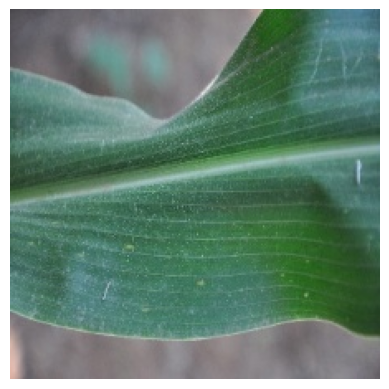

MobileNetV2 | Laboratorio:   0%|          | 0/838 [00:00<?, ?it/s]

MobileNetV2 | Campo:   0%|          | 0/800 [00:00<?, ?it/s]

ResNet-50 | Laboratorio:   0%|          | 0/838 [00:00<?, ?it/s]

ResNet-50 | Campo:   0%|          | 0/800 [00:00<?, ?it/s]

ViT-base | Laboratorio:   0%|          | 0/838 [00:00<?, ?it/s]

ViT-base | Campo:   0%|          | 0/800 [00:00<?, ?it/s]

Dataset,Campo,Laboratorio
Modelo,,
MobileNetV2,7.6,0.5
ResNet-50,6.0,0.4
ViT-base,0.9,0.1


In [8]:
# === 5. Pipeline de inferencia ===
from transformers import pipeline
from transformers.pipelines.pt_utils import KeyDataset
from tqdm.auto import tqdm

clasificadores = {
    nombre: pipeline("image-classification", model=modelos[nombre],
                     image_processor=procesadores[nombre], device=DEVICE)
    for nombre in modelos
}

def a_clase_maiz(salida):
    """Ajuste de salida: de las 38 etiquetas se queda con la clase de maíz de mayor score.
    Devuelve (clase, score, True si el top-1 crudo era de otro cultivo)."""
    maiz = [(clase_maiz(s["label"]), s["score"]) for s in salida if clase_maiz(s["label"])]
    clase, score = max(maiz, key=lambda t: t[1])
    return clase, score, clase_maiz(salida[0]["label"]) is None

# Ejemplo con la primera imagen de campo: salida cruda (top-3) contra salida ajustada
img, real = ds_campo[0]["image"], y_campo[0]
for nombre, clf in clasificadores.items():
    salida = clf(img, top_k=modelos[nombre].config.num_labels)  # las 38 clases ordenadas por score
    pred, score, fuera = a_clase_maiz(salida)
    print(f"{nombre}")
    print("   top-3 crudo:", [(s["label"], round(s["score"], 3)) for s in salida[:3]])
    print(f"   clase de maíz: {pred} ({score:.3f}) | real: {real}")
plt.imshow(img); plt.axis("off"); plt.show()


resultados = []
for nombre, clf in clasificadores.items():
    k = modelos[nombre].config.num_labels
    for n_ds, (ds, y) in DATASETS.items():
        salidas = clf(KeyDataset(ds, "image"), top_k=k, batch_size=32)
        for real, salida in zip(y, tqdm(salidas, total=len(y), desc=f"{nombre} | {n_ds}")):
            pred, score, fuera = a_clase_maiz(salida)
            resultados.append({"Modelo": nombre, "Dataset": n_ds, "Real": real,
                               "Predicción": pred, "Score": score, "Top-1 otro cultivo": fuera})

pred_df = pd.DataFrame(resultados)
pred_df.to_csv("predicciones.csv", index=False)  # se sube al repo junto con el cuaderno

# % de imágenes en que la predicción más alta fue otro cultivo (antes del ajuste)
otro_cultivo = (pred_df.groupby(["Modelo", "Dataset"])["Top-1 otro cultivo"].mean() * 100).round(1).unstack()
display(otro_cultivo.reindex(list(MODELOS)))

,Modelo,Dataset,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,MobileNetV2,Laboratorio,0.896,0.866,0.870,0.868
1,MobileNetV2,Campo,0.725,0.727,0.725,0.725
2,ResNet-50,Laboratorio,0.896,0.869,0.882,0.873
3,ResNet-50,Campo,0.735,0.753,0.735,0.738
4,ViT-base,Laboratorio,0.934,0.914,0.936,0.921
5,ViT-base,Campo,0.765,0.804,0.765,0.771


Dataset,Laboratorio,Campo,Caída (puntos)
Modelo,,,
MobileNetV2,0.868,0.725,14.3
ResNet-50,0.873,0.738,13.5
ViT-base,0.921,0.771,15.0


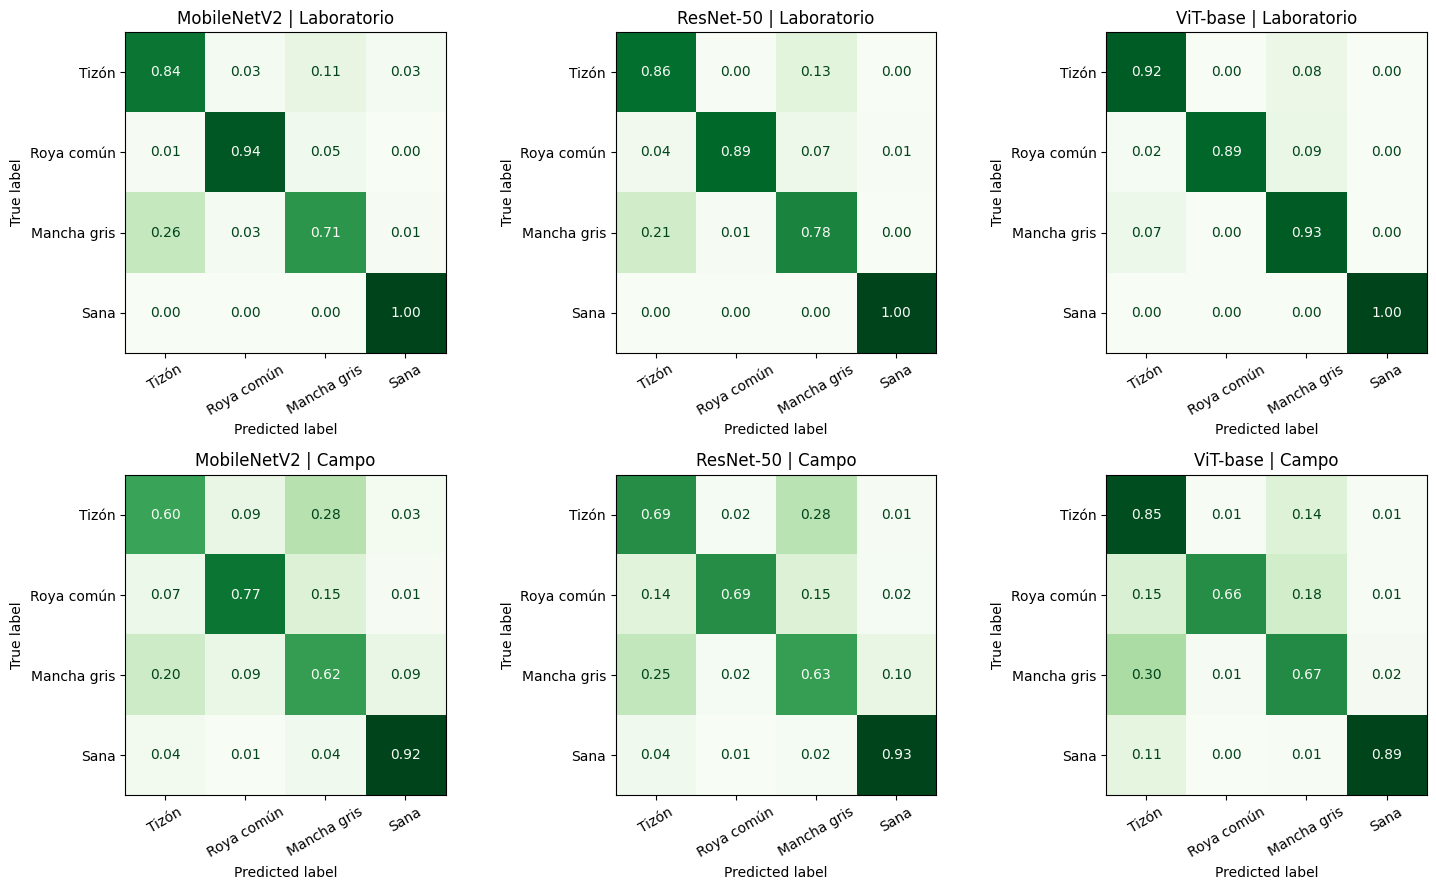

In [9]:
# === 6. Métricas ===
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

filas = []
for (nombre, n_ds), g in pred_df.groupby(["Modelo", "Dataset"], sort=False):
    p, r, f1, _ = precision_recall_fscore_support(g["Real"], g["Predicción"], labels=CLASES,
                                                  average="macro", zero_division=0)
    filas.append({"Modelo": nombre, "Dataset": n_ds,
                  "Accuracy": accuracy_score(g["Real"], g["Predicción"]),
                  "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f1})

metricas = pd.DataFrame(filas).round(3)
metricas.to_csv("metricas.csv", index=False)
display(metricas)

brecha = metricas.pivot(index="Modelo", columns="Dataset", values="F1 (macro)").reindex(list(MODELOS))
brecha["Caída (puntos)"] = ((brecha["Laboratorio"] - brecha["Campo"]) * 100).round(1)
display(brecha[["Laboratorio", "Campo", "Caída (puntos)"]])


fig, ejes = plt.subplots(2, 3, figsize=(15, 9))
for fila, n_ds in enumerate(DATASETS):
    for col, nombre in enumerate(MODELOS):
        g = pred_df[(pred_df["Modelo"] == nombre) & (pred_df["Dataset"] == n_ds)]
        cm = confusion_matrix(g["Real"], g["Predicción"], labels=CLASES, normalize="true")
        ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ejes[fila, col], cmap="Greens",
                                                               values_format=".2f", colorbar=False)
        ejes[fila, col].set_title(f"{nombre} | {n_ds}")
        ejes[fila, col].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [11]:
# === 7. Medición de latencia ===
# Lote de 1 imagen, como en la app. Se toman 50 fotos de campo porque tienen la resolución real de una cámara.

import os, time

N_IMAGENES, N_CALENTAMIENTO = 50, 10
# Las fotos se decodifican antes de medir para no contar la lectura del JPG desde disco
imagenes = [ds_campo[i]["image"].convert("RGB") for i in range(N_IMAGENES)]
print("Resolución de ejemplo:", imagenes[0].size, "| núcleos de CPU:", os.cpu_count(),
      "| hilos de torch:", torch.get_num_threads())

def sincronizar(dispositivo):
    # En GPU las operaciones son asíncronas: sin esperar a que terminen, el cronómetro se detendría antes de tiempo
    if dispositivo == "cuda":
        torch.cuda.synchronize()

def medir(nombre, dispositivo):
    modelo, proc = modelos[nombre].to(dispositivo), procesadores[nombre]
    t_pre, t_inf = [], []
    with torch.inference_mode():
        for i, img in enumerate(imagenes[:N_CALENTAMIENTO] + imagenes):
            t0 = time.perf_counter()
            entrada = proc(img, return_tensors="pt")["pixel_values"].to(dispositivo)
            sincronizar(dispositivo)
            t1 = time.perf_counter()
            modelo(pixel_values=entrada)
            sincronizar(dispositivo)
            t2 = time.perf_counter()
            if i >= N_CALENTAMIENTO:
                t_pre.append((t1 - t0) * 1000)
                t_inf.append((t2 - t1) * 1000)
    total = np.add(t_pre, t_inf)
    return {"Modelo": nombre, "Dispositivo": "GPU T4" if dispositivo == "cuda" else "CPU",
            "Preproceso (ms)": np.median(t_pre), "Inferencia mediana (ms)": np.median(t_inf),
            "Inferencia p95 (ms)": np.percentile(t_inf, 95), "Total mediana (ms)": np.median(total),
            "Imágenes/s": 1000 / np.median(total)}

dispositivos = ["cuda", "cpu"] if torch.cuda.is_available() else ["cpu"]
latencia = pd.DataFrame([medir(nombre, d) for d in dispositivos for nombre in MODELOS]).round(1)
for modelo in modelos.values():
    modelo.to(DEVICE)  # se regresan los modelos a la GPU después de medir en CPU

latencia.to_csv("latencia.csv", index=False)
display(latencia)

# Resumen: latencia total por imagen (mediana) en cada dispositivo
display(latencia.pivot(index="Modelo", columns="Dispositivo", values="Total mediana (ms)").reindex(list(MODELOS)))


Resolución de ejemplo: (224, 224) | núcleos de CPU: 2 | hilos de torch: 1


,Modelo,Dispositivo,Preproceso (ms),Inferencia mediana (ms),Inferencia p95 (ms),Total mediana (ms),Imágenes/s
0,MobileNetV2,CPU,2.8,57.7,65.8,60.6,16.5
1,ResNet-50,CPU,2.1,209.3,313.2,211.4,4.7
2,ViT-base,CPU,1.7,668.7,1065.5,670.6,1.5


Dispositivo,CPU
Modelo,
MobileNetV2,60.6
ResNet-50,211.4
ViT-base,670.6


In [13]:
# === 8. Tablas y resúmenes ===
# --- 8a. Tabla comparativa: precisión contra costo de cada modelo ---
campo = pred_df[pred_df["Dataset"] == "Campo"]
enfermas, sanas = campo[campo["Real"] != "Sana"], campo[campo["Real"] == "Sana"]

# Los dos errores con costo para el productor, medidos en campo
errores = pd.DataFrame({
    "Enferma → Sana campo (%)": enfermas.groupby("Modelo")["Predicción"].apply(lambda p: (p == "Sana").mean() * 100),
    "Sana → Enferma campo (%)": sanas.groupby("Modelo")["Predicción"].apply(lambda p: (p != "Sana").mean() * 100),
})
lat = latencia.pivot(index="Modelo", columns="Dispositivo", values="Total mediana (ms)")[latencia["Dispositivo"].unique()]

resumen = (pd.DataFrame(resumen_modelos).set_index("Modelo")[["Parámetros (M)", "Tamaño en memoria (MB)"]]
           .rename(columns={"Tamaño en memoria (MB)": "Tamaño (MB)"})
           .join([brecha.rename(columns={"Laboratorio": "F1 lab", "Campo": "F1 campo",
                                         "Caída (puntos)": "Caída F1 (pts)"}),
                  otro_cultivo["Campo"].rename("Top-1 otro cultivo campo (%)"),
                  errores,
                  lat.add_prefix("Latencia ").add_suffix(" (ms)")])
           .reindex(list(MODELOS)))
resumen.to_csv("resumen.csv")

# Se muestra transpuesta (una columna por modelo) para que quepa en el informe.
# En F1 gana el valor más alto; en todas las demás filas (tamaño, caída, errores, latencia) gana el más bajo.
mas_alto = ["F1 lab", "F1 campo"]
mas_bajo = [c for c in resumen.columns if c not in mas_alto]
verde = "background-color: #c8e6c9"
display(resumen.T.style
        .format("{:.1f}")
        .format("{:.3f}", subset=pd.IndexSlice[mas_alto, :])
        .highlight_max(axis=1, subset=pd.IndexSlice[mas_alto, :], props=verde)
        .highlight_min(axis=1, subset=pd.IndexSlice[mas_bajo, :], props=verde))

Modelo,MobileNetV2,ResNet-50,ViT-base
Parámetros (M),2.3,23.6,85.8
Tamaño (MB),9.1,94.3,343.3
F1 campo,0.725,0.738,0.771
F1 lab,0.868,0.873,0.921
Caída F1 (pts),14.3,13.5,15.0
Top-1 otro cultivo campo (%),7.6,6.0,0.9
Enferma → Sana campo (%),4.5,4.5,1.0
Sana → Enferma campo (%),8.5,7.0,11.5
Latencia CPU (ms),60.6,211.4,670.6


In [14]:
# --- 8b. F1 por clase en cada dataset ---
# Muestra qué enfermedad le cuesta a cada modelo, algo que el F1 macro promedia y esconde
f1_clase = []
for (nombre, n_ds), g in pred_df.groupby(["Modelo", "Dataset"], sort=False):
    _, _, f1, _ = precision_recall_fscore_support(g["Real"], g["Predicción"], labels=CLASES, zero_division=0)
    f1_clase.append(pd.Series(f1, index=CLASES, name=(n_ds, nombre)))
f1_clase = pd.DataFrame(f1_clase).reindex(pd.MultiIndex.from_product([list(DATASETS), list(MODELOS)],
                                                                     names=["Dataset", "Modelo"]))
f1_clase.to_csv("f1_por_clase.csv")
display(f1_clase.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None))

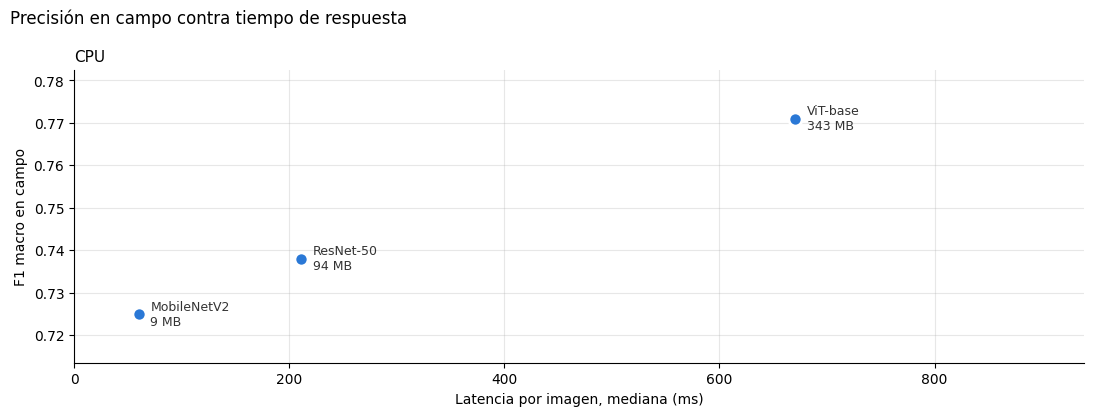

In [15]:
# --- 8c. Gráfica: F1 en campo contra latencia en cada dispositivo ---
# Un panel por dispositivo con el mismo eje de F1; arriba a la izquierda = más preciso y más rápido
fig, ejes = plt.subplots(1, len(lat.columns), figsize=(11, 4.2), sharey=True)
for eje, disp in zip(np.atleast_1d(ejes), lat.columns):
    x, y = resumen[f"Latencia {disp} (ms)"], resumen["F1 campo"]
    eje.scatter(x, y, s=90, color="#2a78d6", edgecolor="white", linewidth=2, zorder=3)
    for nombre in resumen.index:
        eje.annotate(f"{nombre}\n{resumen.loc[nombre, 'Tamaño (MB)']:.0f} MB", (x[nombre], y[nombre]),
                     xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color="#333333")
    eje.set_title(disp, loc="left", fontsize=11)
    eje.set_xlabel("Latencia por imagen, mediana (ms)")
    eje.set_xlim(0, x.max() * 1.4)
    eje.margins(y=0.25)
    eje.grid(alpha=0.3)
    eje.spines[["top", "right"]].set_visible(False)
np.atleast_1d(ejes)[0].set_ylabel("F1 macro en campo")
fig.suptitle("Precisión en campo contra tiempo de respuesta", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("precision_vs_latencia.png", dpi=150, bbox_inches="tight")
plt.show()

## . Conclusiones parciales

1. **La brecha de dominio domina el resultado.** Los tres modelos pierden entre 13.5 y 15 puntos de F1 al pasar de fotos de laboratorio a fotos de campo, y ninguno se acerca al ~95 % que reportan sus fichas. En campo el mejor F1 macro es 0.771 (ViT), por debajo del KPI de F1 ≥ 0.85 en fotos locales que se fijó para el piloto.
2. **ViT-base es el más preciso y el que mejor equilibra los errores para el productor:** mejor F1 en ambos dominios, 0.9 % de confusión con otros cultivos y solo 1.0 % de hojas enfermas diagnosticadas como sanas (4.5 % en los otros dos). Su costo es el tamaño (343 MB), la latencia en CPU (383–671 ms según la sesión) y más falsas alarmas sobre hojas sanas (11.5 %).
3. **ResNet-50 no justifica su costo:** gana 1.3 puntos de F1 sobre MobileNetV2, dentro del margen de la muestra (±3 puntos con n = 800), con 3.5 veces más latencia en CPU y 10 veces más tamaño. La decisión real queda entre ViT y MobileNetV2.
4. **El lugar de ejecución define el modelo.** En un servidor, ViT es la mejor opción (14.9 ms en GPU T4 y menos de 1 s en CPU). MobileNetV2 (9 MB, 55–61 ms en CPU) solo se justifica si la app debe diagnosticar sin conexión en el celular, a cambio de 4.6 puntos de F1 y de más del cuádruple de hojas enfermas no detectadas.
5. **La dificultad está en distinguir enfermedades, no en detectar la hoja enferma.** La clase Sana mantiene F1 ≥ 0.89 en campo, mientras que Mancha gris (0.59–0.67) y Tizón se confunden entre sí. Roya común queda en ~0.79 con los tres modelos, sin ganancia por arquitectura.
6. **Limitaciones:** solo inferencia, sin ajuste fino; dataset de campo sin ficha ni licencia y con imágenes ya reducidas a 224×224; latencia medida en Colab y no en un celular; los modelos no conocen enfermedades locales como la mancha de asfalto o la roya del sur.

**Siguiente paso:** usar ViT-base como candidato preliminar y hacer ajuste fino con fotos de campo etiquetadas localmente. Si la app debe correr sin conexión, repetir la comparación con MobileNetV2 ajustado y cuantizado.